![Banner](../images/03_03_banner_spatial_analysis_multidimentional.png)


# Multidimensional Data Management 

This notebook introduces the basics of working with multidimensional (space-time) environmental datasets using GeoLattice tools. We focus on how multidimensional data, such as NetCDF files that store years of climate or earth observation variables, can be managed, processed, and analyzed efficiently using GeoLattice. Through practical examples, you'll learn approaches to extracting, aggregating, and converting multi-band spatial-temporal data for geospatial analysis.


## Overview

This section introduces the management and analysis of multidimensional geospatial data, 
particularly focusing on datasets with multiple dimensions such as space and time 
(for example, climate variables recorded over several years and locations in NetCDF format). 
The aim is to show how to efficiently work with these complex data structures in GeoLattice, 
including data extraction, aggregation, transformation, and conversion into GIS-friendly formats 
for further spatial analysis.

 This chapter covers:

**Sections 2-13. Multidimensional Raster Creation from ERA NetCDF**  
Learn how to process and analyze multidimensional climate data (e.g., ERA NetCDF temperature): extraction, aggregation, transformation, masking, and rasterization steps.

**Section 14. Raster to NetCDF**  
Explore techniques for converting raster data to NetCDF format, including handling, visualization, and extracting temporal and spatial information.

**Section 15. Table to NetCDF**  
Discover approaches for exporting processed table data to NetCDF and other formats, ensuring interoperability with GIS tools and workflows.



## Multidimensional Raster Creation from ERA NetCDF

This notebook demonstrates the full processing pipeline for handling **2 m air temperature** (`t2m`)
data from the ECMWF ERA merged NetCDF (`Data/03_spatial_analysis/NetCDF/t2m_2000_2018.nc`).

1. **Extract annual temperature**: Selects data for a target year (e.g., **2018**) from the multiyear NetCDF.
2. **Temporal aggregation to daily means**: Converts 3-hourly (sub-daily) values to daily average temperature in Celsius.
3. **Spatial transformation**: Constructs spatial point features for temperature values and reprojects them to the Bangladesh Transverse Mercator (**BUTM**) coordinate system.
4. **Boundary masking**: Clips the points to the Bangladesh official boundary using a shapefile mask.
5. **16-day MODIS-style temporal aggregation**: Aggregates daily temperature values into 16-day means,
   matching MODIS NDVI temporal granularity (output format: CSV columns like `D_YYYY_017`, `D_YYYY_033` ...).
6. **Spatial interpolation and rasterization**: Applies thin-plate spline interpolation over the entire Bangladesh domain at **1000 m** spatial resolution, and exports the results as a multi-band GeoTIFF (one band per 16-day period).



### Output products

| Output type | Path location |
|---|---|
| 16-day mean temperature CSV (all years) | `Data/03_spatial_analysis/NetCDF/output/Tabular_Data/t2m_YYYY_mean_16days.csv` |
| Multi-band raster (GeoTIFF) for all years | `Data/03_spatial_analysis/NetCDF/output/Raster_Data/t2m_YYYY_16day_1000m.tif` |

> **Note:** The available years in `t2m_2000_2018.nc` are **2000-2003**, **2007-2018** (years **2004-2006** are absent).

### Dependencies
- netCDF data I/O and manipulation: `xarray`, `netCDF4`
- Vector GIS operations: `geopandas`
- Raster creation and export: `rasterio`
- Geometric and spatial transformation: `shapely`
- Interpolation: `scipy.interpolate`
- Data handling: `numpy`, `pandas`


## Setup

Locate the repository root, import the processing libraries, and create the output folders.

**Installation.** This notebook needs installation option 2 (core plus spatial analysis): `pip install "geolattice[analysis]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

# Standard library imports for optional GDAL path setup.
import os  # environment variables for GDAL and process paths
import warnings  # silence noisy third-party warnings in the tutorial
from pathlib import Path  # filesystem paths for locating sample data

# Point PATH and GDAL_DATA at the user-local GDAL build when it is present.
# Do not preload libgdal and do not set PROJ_DATA. pyogrio ships its own proj.db,
# and the newer PROJ in gdal-prefix rejects that file, so GeoPandas cannot open
# the boundary shapefile.
_GDAL_PREFIX = Path.home() / ".local" / "share" / "gdal-prefix"  # local GDAL install prefix
_GDAL_LIBDIR = _GDAL_PREFIX / "lib"  # directory containing libgdal
_GDAL_SO = _GDAL_LIBDIR / "libgdal.so.39"  # shared library used by osgeo
if _GDAL_SO.is_file():  # only adjust the environment when the local build exists
    os.environ["PATH"] = f"{_GDAL_PREFIX / 'bin'}{os.pathsep}{os.environ.get('PATH', '')}"  # prepend GDAL bin
    _gdal_data = _GDAL_PREFIX / "share" / "gdal"  # GDAL_DATA support files
    if _gdal_data.is_dir():
        os.environ.setdefault("GDAL_DATA", str(_gdal_data))  # set GDAL_DATA if not already defined


# Third-party numeric / geospatial stack for temperature management.
import numpy as np  # array ops for grids, masks, and numeric summaries
import pandas as pd  # tabular composites and CSV export
import xarray as xr  # labeled NetCDF / multidimensional arrays
import geopandas as gpd  # Bangladesh boundary and point GeoDataFrames
import matplotlib.pyplot as plt  # figure and axes creation for maps
import rasterio  # GeoTIFF I/O for interpolated surfaces
from rasterio.transform import from_bounds  # affine transform from map bounds
from rasterio.features import geometry_mask  # rasterize the boundary mask
from shapely.geometry import Point  # point geometries (available for helpers)
from scipy.interpolate import RBFInterpolator  # thin-plate spline interpolation

warnings.filterwarnings("ignore")  # keep the tutorial output readable

# The installed package lives in src/; the repository root is its parent.
import geolattice

ROOT = Path(geolattice.__file__).resolve().parents[1]
if not (ROOT / "Data").is_dir():
    raise FileNotFoundError("Could not find the GeoLattice repository root.")

# Multidimensional management helpers used below.
from geolattice.spatial_analysis import (
    MultidimensionalRaster,  # cube wrapper around an xarray Dataset
    build_multidimensional_info,  # build cube metadata tables
    merge_multidimensional_rasters,  # merge cubes
    raster_to_netcdf,  # GeoTIFF series to NetCDF
    table_to_netcdf,  # tabular composites to NetCDF
)

# Input NetCDF, Bangladesh boundary, watertable tiles, and output folders.
NC_PATH = ROOT / "Data" / "03_spatial_analysis" / "NetCDF" / "t2m_2000_2018.nc"  # ERA5 2 m temperature cube
BD_SHP = (  # BD_SHP
    ROOT / "Data" / "00_shared" / "vector_data" / "Bangladesh" / "Shapefiles" / "BD_Banladesh_BUTM.shp"
)  # Bangladesh boundary in BUTM
WT_DIR = ROOT / "Data" / "00_shared" / "raster_data" / "Bangladesh" / "watertable"  # watertable GeoTIFF series
TAB_DIR = ROOT / "Data" / "03_spatial_analysis" / "NetCDF" / "output" / "Tabular_Data"  # CSV composite outputs
RAS_DIR = ROOT / "Data" / "03_spatial_analysis" / "NetCDF" / "output" / "Raster_Data"  # interpolated GeoTIFF outputs
NC_OUT_DIR = ROOT / "Data" / "03_spatial_analysis" / "NetCDF" / "output"  # parent NetCDF output folder
TAB_DIR.mkdir(parents=True, exist_ok=True)  # ensure tabular output folder exists
RAS_DIR.mkdir(parents=True, exist_ok=True)  # ensure raster output folder exists
NC_OUT_DIR.mkdir(parents=True, exist_ok=True)  # ensure NetCDF output folder exists

# MODIS 16-day composite start DOYs (column labels use these values).
MODIS_DOYS = [  # MODIS_DOYS
    1, 17, 33, 49, 65, 81, 97, 113, 129, 145, 161, 177,
    193, 209, 225, 241, 257, 273, 289, 305, 321, 337, 353,
]  # standard MODIS 16-day start days

DEMO_YEAR = 2018  # year used for the single-year walkthrough
RESOLUTION_M = 1000.0  # target grid resolution for TPS interpolation (metres)

print("Repo:   ", ROOT)  # confirm repository root
print("NetCDF: ", NC_PATH, "exists=" + str(NC_PATH.is_file()))  # confirm temperature cube
print("Watertable:", WT_DIR, "exists=" + str(WT_DIR.is_dir()))  # confirm watertable folder
print("Boundary:", BD_SHP, "exists=" + str(BD_SHP.is_file()))  # confirm boundary shapefile
print("Tabular:", TAB_DIR)  # tabular output folder
print("Raster: ", RAS_DIR)  # raster output folder
print("NC out: ", NC_OUT_DIR)  # NetCDF output folder

# Confirm GDAL bindings resolve (needed by build_multidimensional_info / open_raster_data).
try:  # attempt optional or version-sensitive call
    from osgeo import gdal  # GDAL Python bindings
    print("GDAL:   ", gdal.__version__, "(osgeo OK)")  # confirm version
except Exception as _exc:  # handle the failure path
    print("GDAL:    FAILED, ", _exc)  # report import failure
    print("         Expected lib at", _GDAL_SO)  # hint where libgdal should be


Repo:    /home/zia207/Github/GeoLattice
NetCDF:  /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/NetCDF/t2m_2000_2018.nc exists=True
Watertable: /home/zia207/Github/GeoLattice/Data/00_shared/raster_data/Bangladesh/watertable exists=True
Boundary: /home/zia207/Github/GeoLattice/Data/00_shared/vector_data/Bangladesh/Shapefiles/BD_Banladesh_BUTM.shp exists=True
Tabular: /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/NetCDF/output/Tabular_Data
Raster:  /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/NetCDF/output/Raster_Data
NC out:  /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/NetCDF/output
GDAL:    3.13.3 (osgeo OK)


## Helper functions

Shared utilities for daily averaging, clipping, 16-day composites, TPS, and GeoTIFF writing.


In [2]:
# --- Helper functions for multidimensional temperature data processing ---
# Each function includes comments explaining its role and main steps.

def load_year_t2m_celsius(nc_path: Path, year: int) -> xr.DataArray:
    """
    Load temperature (t2m) data for a given year from a NetCDF file and convert from Kelvin to Celsius.
    
    Steps:
    1. Open the NetCDF dataset.
    2. Select temperature values (t2m) for the specified year only.
    3. Check if data exists for this year.
    4. Convert temperature from Kelvin to Celsius.
    5. Attach relevant attributes and load data into memory.
    6. Close the dataset and return the result.
    """
    ds = xr.open_dataset(nc_path)  # open the NetCDF dataset
    t2m = ds["t2m"].sel(time=slice(f"{year}-01-01", f"{year}-12-31"))  # select one calendar year of t2m
    if t2m.sizes.get("time", 0) == 0:  # abort if the year has no timesteps
        ds.close()  # close the NetCDF handle
        raise ValueError(f"No t2m timesteps found for year {year}")  # fail with a clear error message
    t2m_c = (t2m - 273.15).astype("float32")  # Kelvin to Celsius as float32
    t2m_c.attrs.update({"units": "degC", "long_name": "2 metre temperature"})  # attach CF-style units metadata
    out = t2m_c.load()  # load the array into memory
    ds.close()  # close the NetCDF handle
    return out  # return the result

def to_daily_mean(t2m_3h: xr.DataArray) -> xr.DataArray:
    """
    Convert 3-hourly temperature data into daily averages.
    
    Steps:
    1. Use xarray's resample to average all 3-hourly values within each calendar day.
    2. Update metadata for clarity.
    3. Return the daily mean DataArray.
    """
    daily = t2m_3h.resample(time="1D").mean(skipna=True)  # average 3-hourly values to daily means
    daily.name = "t2m"  # set the DataArray name
    daily.attrs.update({"units": "degC", "long_name": "Daily mean 2 metre temperature"})  # attach CF-style units metadata
    return daily  # return the result

def daily_to_points(daily: xr.DataArray) -> gpd.GeoDataFrame:
    """
    Convert daily gridded temperature to a GeoDataFrame with a row per 2D grid point and columns for each date.
    
    Steps:
    1. Generate 2D longitude and latitude arrays representing each grid node.
    2. Flatten arrays to build table rows; assign unique station ids.
    3. Move daily temp values into a (points x time) table.
    4. Build a pandas DataFrame for values and locations.
    5. Convert to GeoDataFrame with geometry column (EPSG:4326).
    """
    lon2d, lat2d = np.meshgrid(daily.longitude.values, daily.latitude.values)  # 2-D lon/lat grids for each cell
    n_pts = lon2d.size  # n_pts
    station_id = [f"S{i:04d}" for i in range(n_pts)]  # stable point identifiers

    vals = np.moveaxis(daily.values, 0, -1).reshape(n_pts, daily.sizes["time"])  # reshape cube to points x time
    dates = pd.to_datetime(daily.time.values).strftime("%Y-%m-%d")  # date strings as column labels
    df = pd.DataFrame(vals, columns=dates)  # build the attribute table
    df.insert(0, "station_id", station_id)  # prepend id / coordinate columns
    df.insert(1, "lon", lon2d.ravel().astype("float64"))  # prepend id / coordinate columns
    df.insert(2, "lat", lat2d.ravel().astype("float64"))  # prepend id / coordinate columns

    geometry = gpd.points_from_xy(df["lon"], df["lat"], crs="EPSG:4326")  # build point geometries in WGS84
    return gpd.GeoDataFrame(df, geometry=geometry, crs="EPSG:4326")  # return the result

def reproject_and_clip(gdf: gpd.GeoDataFrame, bd: gpd.GeoDataFrame) -> gpd.GeoDataFrame:
    """
    Reproject the points to the coordinate reference system (CRS) of `bd` and clip them to Bangladesh's boundary.
    
    Steps:
    1. Project all point geometries into the same CRS as the Bangladesh boundary (BUTM).
    2. Clip points to those inside the boundary polygon.
    3. Reset the index for a clean output.
    """
    proj = gdf.to_crs(bd.crs)  # reproject to the boundary CRS
    clipped = gpd.clip(proj, bd)  # keep points inside Bangladesh
    return clipped.reset_index(drop=True)  # return the result

def modis_16day_means(clipped: gpd.GeoDataFrame, year: int) -> pd.DataFrame:
    """
    Average daily columns into MODIS-like 16-day intervals for each point.
    
    Output table columns: station_id, lon, lat, and one column per 16-day composite (D_{year}_{start_DOY}).
    
    Steps:
    1. Identify which columns are dates (exclude id/lon/lat/geometry).
    2. Convert column headers to datetime to extract day-of-year.
    3. Prepare output DataFrame for ids and point locations (in WGS84).
    4. For each 16-day MODIS interval, calculate the mean across all matching days per row.
    5. Assign results to output table.
    """
    date_cols = [c for c in clipped.columns if c not in {"station_id", "lon", "lat", "geometry"}]  # daily value columns only
    dates = pd.to_datetime(date_cols)  # daily value columns only
    doys = dates.dayofyear.to_numpy()  # DOY for each daily column

    wgs = clipped.to_crs("EPSG:4326")  # reproject to the boundary CRS
    out = pd.DataFrame({  # build the attribute table
        "station_id": clipped["station_id"].values,
        "lon": wgs.geometry.x.values,
        "lat": wgs.geometry.y.values,
    })

    starts = MODIS_DOYS  # 16-day composite start DOYs
    for i, start in enumerate(starts):  # iterate over items
        end = starts[i + 1] if i + 1 < len(starts) else 367  # end
        mask = (doys >= start) & (doys < end)  # mask
        cols = [date_cols[j] for j, m in enumerate(mask) if m]  # daily value columns only
        name = f"D_{year}_{start:03d}"  # name
        if cols:
            out[name] = clipped[cols].mean(axis=1, skipna=True).astype("float32").values  # mean of days in this 16-day window
        else:
            out[name] = np.nan  # no days in this window
    return out  # return the result

def make_target_grid(bd: gpd.GeoDataFrame, resolution_m: float = 1000.0):
    """
    Create a regular raster grid (width x height, meters per pixel) covering the extent of Bangladesh.
    
    Steps:
    1. Compute the full bounding box (total_bounds) for bd.
    2. Convert to integer grid width/height using resolution.
    3. Calculate affine transform mapping pixel to map coordinates.
    4. Generate evenly spaced grid points for X/Y pixel centers.
    5. Stack to Nx2 array of coordinates for interpolation.
    6. Create a mask so only grid cells inside bd geometry are True.
    7. Return all grid-related parameters.
    """
    bounds = bd.total_bounds  # boundary extent in projected metres
    width = int(np.ceil((bounds[2] - bounds[0]) / resolution_m))  # grid size from extent and resolution
    height = int(np.ceil((bounds[3] - bounds[1]) / resolution_m))  # grid size from extent and resolution
    transform = from_bounds(bounds[0], bounds[1], bounds[2], bounds[3], width, height)  # affine transform for the target grid
    xs = bounds[0] + (np.arange(width) + 0.5) * resolution_m  # pixel-centre coordinates
    ys = bounds[3] - (np.arange(height) + 0.5) * resolution_m  # pixel-centre coordinates
    X, Y = np.meshgrid(xs, ys)  # 2-D lon/lat grids for each cell
    grid_xy = np.column_stack([X.ravel(), Y.ravel()])  # Nx2 array of grid centres for RBF
    mask = geometry_mask(  # True inside the Bangladesh polygon
        bd.geometry, out_shape=(height, width), transform=transform, invert=True  # GeoTIFF creation option
    )
    return width, height, transform, grid_xy, mask  # return the result

def tps_interpolate_band(coords_xy, values, grid_xy, height, width, mask):
    """
    Interpolate scattered point data onto a raster grid using Thin Plate Spline (RBF).
    
    Steps:
    1. Identify valid (not NaN) values among the points.
    2. If fewer than 3 valid points, output a raster of NaNs.
    3. Fit a thin-plate spline RBF interpolator to these points.
    4. Predict/interpolate values at all grid pixel centers.
    5. Mask out pixels falling outside the target boundary.
    6. Return the interpolated raster array.
    """
    valid = np.isfinite(values)  # valid-value mask
    if valid.sum() < 3:
        return np.full((height, width), np.nan, dtype="float32")  # return the result
    rbf = RBFInterpolator(  # fit thin-plate spline to valid points
        coords_xy[valid], values[valid], kernel="thin_plate_spline", smoothing=0.0  # set coords_xy[valid]
    )
    pred = rbf(grid_xy).reshape(height, width).astype("float32")  # reshape cube to points x time
    pred[~mask] = np.nan  # nodata outside the boundary
    return pred  # return the result

def write_multiband_geotiff(path: Path, bands, band_names, transform, crs):
    """
    Write several raster bands into a single (multi-band) GeoTIFF file.
    
    Steps:
    1. Use rasterio to open/create the output TIFF, specify shape/CRS/transform.
    2. Write each 2D array (one for each composite) as a new band.
    3. Save descriptive names for each band in the TIFF metadata.
    """
    height, width = bands[0].shape  # height
    with rasterio.open(  # write the multi-band GeoTIFF
        path,
        "w",
        driver="GTiff",  # driver
        height=height,  # height
        width=width,  # width
        count=len(bands),  # GeoTIFF creation option
        dtype="float32",  # GeoTIFF creation option
        crs=crs,  # GeoTIFF creation option
        transform=transform,  # GeoTIFF creation option
        nodata=np.nan,  # GeoTIFF creation option
        compress="lzw",  # GeoTIFF creation option
    ) as dst:
        for i, (arr, name) in enumerate(zip(bands, band_names), start=1):  # iterate over items
            dst.write(arr, i)  # write one band
            dst.set_band_description(i, name)

def process_year(nc_path, year, bd, tab_dir, ras_dir, grid_cache, resolution_m=1000.0):
    """
    Complete workflow for processing one year of temperature data:
        → Save Bangladesh-clipped, MODIS-16day mean temperatures (tabular and raster).
    
    Steps (with logging):
    1. Load temperature for one year and convert to Celsius.
    2. Average to daily means.
    3. Convert daily gridded data to spatial points.
    4. Reproject and clip to Bangladesh.
    5. Tabulate 16-day means, save to CSV.
    6. For each composite, interpolate to grid, stack results as raster bands.
    7. Write all bands to a single GeoTIFF (one band per composite).
    8. Return paths to output files.
    """
    print(f"\n=== Year {year} ===")  # status / summary print
    t2m = load_year_t2m_celsius(nc_path, year)  # t2m
    print(f"  3-hourly: {t2m.sizes['time']} steps")  # status / summary print
    daily = to_daily_mean(t2m)  # aggregate along time or groups
    print(f"  daily:    {daily.sizes['time']} days")  # status / summary print

    gdf = daily_to_points(daily)  # gdf
    clipped = reproject_and_clip(gdf, bd)  # reproject or clip geometries
    print(f"  points after clip: {len(clipped)}")  # status / summary print

    table = modis_16day_means(clipped, year)  # table
    csv_path = tab_dir / f"t2m_{year}_mean_16days.csv"  # csv_path
    table.to_csv(csv_path, index=False)  # set table.to_csv(csv_path
    print(f"  CSV → {csv_path.name}  ({table.shape[1] - 3} composites)")  # status / summary print

    width, height, transform, grid_xy, mask = grid_cache  # width
    coords_xy = np.column_stack([clipped.geometry.x.values, clipped.geometry.y.values])  # Nx2 array of grid centres for RBF
    band_cols = [c for c in table.columns if c.startswith(f"D_{year}_")]  # band_cols
    bands = []  # bands
    for col in band_cols:  # iterate over items
        arr = tps_interpolate_band(  # arr
            coords_xy, table[col].to_numpy(), grid_xy, height, width, mask
        )
        bands.append(arr)
        print(f"  TPS {col}")  # status / summary print

    tif_path = ras_dir / f"t2m_{year}_16day_1000m.tif"  # tif_path
    write_multiband_geotiff(tif_path, bands, band_cols, transform, bd.crs)
    print(f"  GeoTIFF → {tif_path.name}  ({len(bands)} bands, {width}×{height} @ {resolution_m:.0f} m)")  # status / summary print
    return csv_path, tif_path  # return the result

print("Helpers ready.")  # Indicator that helpers have been defined and are ready for use


Helpers ready.


## Extract temperature for 2018

Open the merged NetCDF and select `t2m` for calendar year 2018 (Kelvin -> °C).


In [3]:
ds_meta = xr.open_dataset(NC_PATH)  # open the NetCDF / dataset
print(ds_meta)  # status / summary print
print("time:", ds_meta.time.values[0], "->", ds_meta.time.values[-1])  # status / summary print
ds_meta.close()  # release the file handle

t2m_2018 = load_year_t2m_celsius(NC_PATH, DEMO_YEAR)  # t2m_2018
print(t2m_2018)  # status / summary print
print(f"°C range: {float(t2m_2018.min()):.2f} -> {float(t2m_2018.max()):.2f}")  # status / summary print


<xarray.Dataset> Size: 366MB
Dimensions:    (time: 45552, latitude: 49, longitude: 41)
Coordinates:
  * time       (time) datetime64[ns] 364kB 2000-01-01T03:00:00 ... 2019-01-01
  * latitude   (latitude) float32 196B 26.5 26.38 26.25 ... 20.75 20.62 20.5
  * longitude  (longitude) float32 164B 87.5 87.62 87.75 ... 92.25 92.38 92.5
Data variables:
    t2m        (time, latitude, longitude) float32 366MB ...
Attributes:
    Conventions:  CF-1.6
    history:      2020-08-23 15:13:57 GMT by grib_to_netcdf-2.18.0: grib_to_n...
    title:        2 metre temperature (t2m) 2000-2018
    source:       Merged from yearly ERA NetCDF files (data_YYYY_fc.nc)
    note:         Years 2004-2006 not present in source directory
time: 2000-01-01T03:00:00.000000000 -> 2019-01-01T00:00:00.000000000


<xarray.DataArray 't2m' (time: 2920, latitude: 49, longitude: 41)> Size: 23MB
array([[[ 7.8530884,  7.675293 ,  7.4286804, ...,  8.590729 ,
          9.207581 ,  9.679413 ],
        [ 8.677643 ,  8.58847  ,  8.419708 , ...,  9.595886 ,
         10.048523 , 10.334076 ],
        [ 9.026428 ,  8.938385 ,  9.02417  , ..., 10.153473 ,
         10.244904 , 10.529358 ],
        ...,
        [22.48288  , 22.694519 , 22.90561  , ..., 21.289795 ,
         20.633972 , 19.97818  ],
        [22.649353 , 22.861572 , 23.073792 , ..., 21.472626 ,
         20.815155 , 20.158783 ],
        [22.58728  , 22.7995   , 23.011688 , ..., 21.416779 ,
         20.759277 , 20.101776 ]],

       [[15.228882 , 15.186249 , 14.983795 , ..., 16.31781  ,
         16.741608 , 17.009369 ],
        [15.90155  , 16.065125 , 16.044617 , ..., 17.30307  ,
         17.549774 , 17.61618  ],
        [16.0997   , 16.264343 , 16.455994 , ..., 17.682037 ,
         17.74466  , 17.809998 ],
...
        [21.83902  , 22.05606  , 22.272

## Convert 3-hourly data to daily averages

Average the 3-hourly 2018 temperatures to one mean per calendar day.


<xarray.DataArray 't2m' (time: 365, latitude: 49, longitude: 41)> Size: 3MB
array([[[14.366299 , 14.296024 , 14.10648  , ..., 14.90086  ,
         15.453114 , 15.815292 ],
        [15.3499565, 15.433086 , 15.378651 , ..., 16.03585  ,
         16.37215  , 16.489094 ],
        [15.819309 , 15.903725 , 16.03342  , ..., 16.588459 ,
         16.639637 , 16.75557  ],
        ...,
        [21.829956 , 21.990704 , 22.151314 , ..., 21.72509  ,
         21.195358 , 20.665424 ],
        [21.973175 , 22.134132 , 22.294952 , ..., 21.917252 ,
         21.386646 , 20.85617  ],
        [22.0929   , 22.253986 , 22.414932 , ..., 22.02129  ,
         21.490467 , 20.959446 ]],

       [[13.694649 , 13.610634 , 13.441044 , ..., 14.479752 ,
         15.043507 , 15.453606 ],
        [14.721607 , 14.747456 , 14.674438 , ..., 15.599644 ,
         15.989155 , 16.201122 ],
        [15.183403 , 15.210869 , 15.3125   , ..., 16.082008 ,
         16.23621  , 16.4473   ],
...
        [20.634647 , 20.773533 , 20.91227

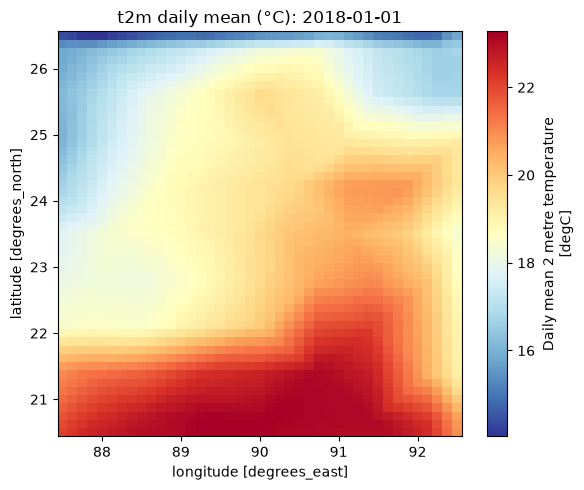

In [4]:
daily_2018 = to_daily_mean(t2m_2018)  # aggregate along time or groups
print(daily_2018)  # status / summary print
print(f"Daily °C range: {float(daily_2018.min()):.2f} -> {float(daily_2018.max()):.2f}")  # status / summary print

fig, ax = plt.subplots(figsize=(6, 5))  # create the figure and axes
daily_2018.isel(time=0).plot(ax=ax, cmap="RdYlBu_r")  # draw the map or chart
ax.set_title(f"t2m daily mean (°C): {np.datetime_as_string(daily_2018.time.values[0], unit='D')}")  # panel title
plt.tight_layout()  # reduce unused whitespace
plt.show()  # render the figure


## Spatial points and reproject to BUTM

Build point features from the daily grid and reproject them to Bangladesh Transverse Mercator (BUTM).


In [5]:
bd = gpd.read_file(BD_SHP)  # read the vector layer
print("Boundary CRS:", bd.crs)  # status / summary print
print("Bounds (m):", bd.total_bounds)  # status / summary print

gdf_2018 = daily_to_points(daily_2018)  # gdf_2018
print("WGS84 points:", len(gdf_2018))  # status / summary print

gdf_butm = gdf_2018.to_crs(bd.crs)  # reproject to the target CRS
print("Reprojected to BUTM")  # status / summary print
print(gdf_butm[["station_id", "lon", "lat"]].head())  # status / summary print


Boundary CRS: PROJCS["Bangladesh Universal Tranverse Mercator (BUTM_2010)",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",90],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Bounds (m): [ 298521.65901686 2276992.71955721  778071.3454779  2946935.05305094]
WGS84 points: 2009
Reprojected to BUTM
  station_id     lon   lat
0      S0000  87.500  26.5
1      S0001  87.625  26.5
2      S0002  87.750  26.5
3      S0003  87.875  26.5
4      S0004  88.000  26.5


## Clip to Bangladesh boundary

Keep only the points that fall inside the Bangladesh boundary.


Points inside Bangladesh: 797


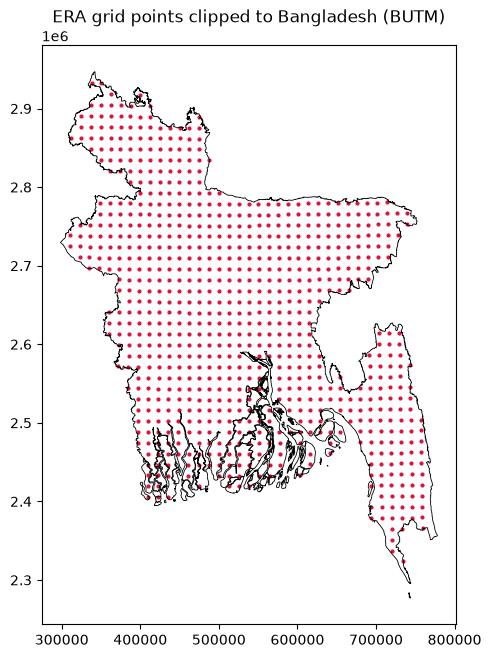

In [6]:
clipped_2018 = reproject_and_clip(gdf_2018, bd)  # reproject or clip geometries
print("Points inside Bangladesh:", len(clipped_2018))  # status / summary print

fig, ax = plt.subplots(figsize=(5, 7))  # create the figure and axes
bd.boundary.plot(ax=ax, color="k", linewidth=0.6)  # draw the map or chart
clipped_2018.plot(ax=ax, markersize=4, color="crimson")  # draw the map or chart
ax.set_title("ERA grid points clipped to Bangladesh (BUTM)")  # panel title
ax.set_aspect("equal")  # style the axes
plt.tight_layout()  # reduce unused whitespace
plt.show()  # render the figure


## MODIS 16-day averages -> CSV (demo 2018)

Windows follow MODIS composite start DOYs (`001`, `017`, `033`, …).
Columns: `station_id`, `lon`, `lat`, `D_2018_001`, `D_2018_017`, …


In [7]:
table_2018 = modis_16day_means(clipped_2018, DEMO_YEAR)  # table_2018
csv_2018 = TAB_DIR / f"t2m_{DEMO_YEAR}_mean_16days.csv"  # csv_2018
table_2018.to_csv(csv_2018, index=False)  # set table_2018.to_csv(csv_2018
print(table_2018.head())  # status / summary print
print("Saved:", csv_2018)  # status / summary print
print("Columns:", list(table_2018.columns[:8]), "...")  # status / summary print


  station_id     lon     lat  D_2018_001  D_2018_017  D_2018_033  D_2018_049  \
0      S1573  89.375  21.750   17.507721   19.554756   22.312443   24.694998   
1      S1572  89.250  21.750   17.456564   19.539871   22.332142   24.720406   
2      S1531  89.250  21.875   16.479610   18.828053   21.950613   24.752777   
3      S1491  89.375  22.000   15.553698   18.131170   21.549423   24.759789   
4      S1490  89.250  22.000   15.502628   18.116268   21.569134   24.785158   

   D_2018_065  D_2018_081  D_2018_097  ...  D_2018_209  D_2018_225  \
0   26.201729   26.924343   27.758171  ...   27.707907   28.103132   
1   26.259951   26.976793   27.777960  ...   27.731861   28.127153   
2   26.251614   27.016556   27.736694  ...   27.521881   27.960423   
3   26.185152   27.004044   27.675732  ...   27.288031   27.769724   
4   26.243279   27.056404   27.695482  ...   27.311934   27.793705   

   D_2018_241  D_2018_257  D_2018_273  D_2018_289  D_2018_305  D_2018_321  \
0   27.495264   27.95

## Thin-plate spline -> 1000 m multi-band GeoTIFF (demo 2018)

Interpolate each 16-day column with a thin-plate spline RBF onto a 1000 x 1000 m
BUTM grid, mask to Bangladesh, and stack bands into one GeoTIFF.


In [8]:
width, height, transform, grid_xy, mask = make_target_grid(bd, RESOLUTION_M)  # width
print(f"Target grid: {width} x {height} @ {RESOLUTION_M:.0f} m")  # status / summary print

coords_xy = np.column_stack([clipped_2018.geometry.x.values, clipped_2018.geometry.y.values])  # stack coordinate columns
band_cols = [c for c in table_2018.columns if c.startswith(f"D_{DEMO_YEAR}_")]  # band_cols
bands = []  # bands
for col in band_cols:  # iterate over items
    arr = tps_interpolate_band(  # arr
        coords_xy, table_2018[col].to_numpy(), grid_xy, height, width, mask
    )
    bands.append(arr)

tif_2018 = RAS_DIR / f"t2m_{DEMO_YEAR}_16day_1000m.tif"  # tif_2018
write_multiband_geotiff(tif_2018, bands, band_cols, transform, bd.crs)
print("Saved:", tif_2018)  # status / summary print


Target grid: 480 x 670 @ 1000 m


Saved: /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/NetCDF/output/Raster_Data/t2m_2018_16day_1000m.tif


## Raster statistics

Summarize each band of the 2018 16-day GeoTIFF.


In [9]:
# Get raster statistics (min, max, mean, std, count of nodata) for tif_2018 as a DataFrame

import rasterio  # GeoTIFF I/O and raster metadata
import pandas as pd  # tabular data frames and datetime indexes
import numpy as np  # array ops for rasters, masks, and numeric summaries

with rasterio.open(tif_2018) as src:  # open a context-managed resource
    n_bands = src.count  # n_bands
    band_names = [src.descriptions[i-1] if src.descriptions[i-1] else f"Band_{i}" for i in range(1, n_bands+1)]  # band_names
    stats = []  # stats
    for b in range(1, n_bands+1):  # iterate over items
        arr = src.read(b).astype(float)  # cast to the target dtype
        nodata = src.nodata  # nodata
        if nodata is not None:
            arr = np.where(arr == nodata, np.nan, arr)  # compute arr
        stat = {  # stat
            "band": band_names[b-1],
            "min": np.nanmin(arr),
            "max": np.nanmax(arr),
            "mean": np.nanmean(arr),
            "std": np.nanstd(arr),
            "count_nodata": np.isnan(arr).sum(),
            "count_valid": np.isfinite(arr).sum()
        }
        stats.append(stat)
        
stats_df = pd.DataFrame(stats)  # compute stats_df
print(stats_df)  # status / summary print
 


          band        min        max       mean       std  count_nodata  \
0   D_2018_001  12.304704  20.175762  15.275033  0.963650        180955   
1   D_2018_017  13.643877  20.719612  16.756985  0.824289        180955   
2   D_2018_033  15.102073  22.576151  19.632771  0.972841        180955   
3   D_2018_049  17.822489  24.808203  22.959870  1.109775        180955   
4   D_2018_065  18.888124  26.421320  24.515388  1.080615        180955   
5   D_2018_081  21.064987  27.404716  25.674222  1.027958        180955   
6   D_2018_097  21.791513  28.090622  26.257581  1.245417        180955   
7   D_2018_113  21.525986  28.896894  26.309733  1.391490        180955   
8   D_2018_129  22.552168  28.923777  26.048767  1.309404        180955   
9   D_2018_145  23.616369  28.933607  27.412539  0.898785        180955   
10  D_2018_161  24.604267  29.746906  28.060475  1.135327        180955   
11  D_2018_177  24.339766  28.262985  27.123664  0.790011        180955   
12  D_2018_193  24.796995

## Plot all rasters

Map every 16-day temperature band from the demo GeoTIFF.


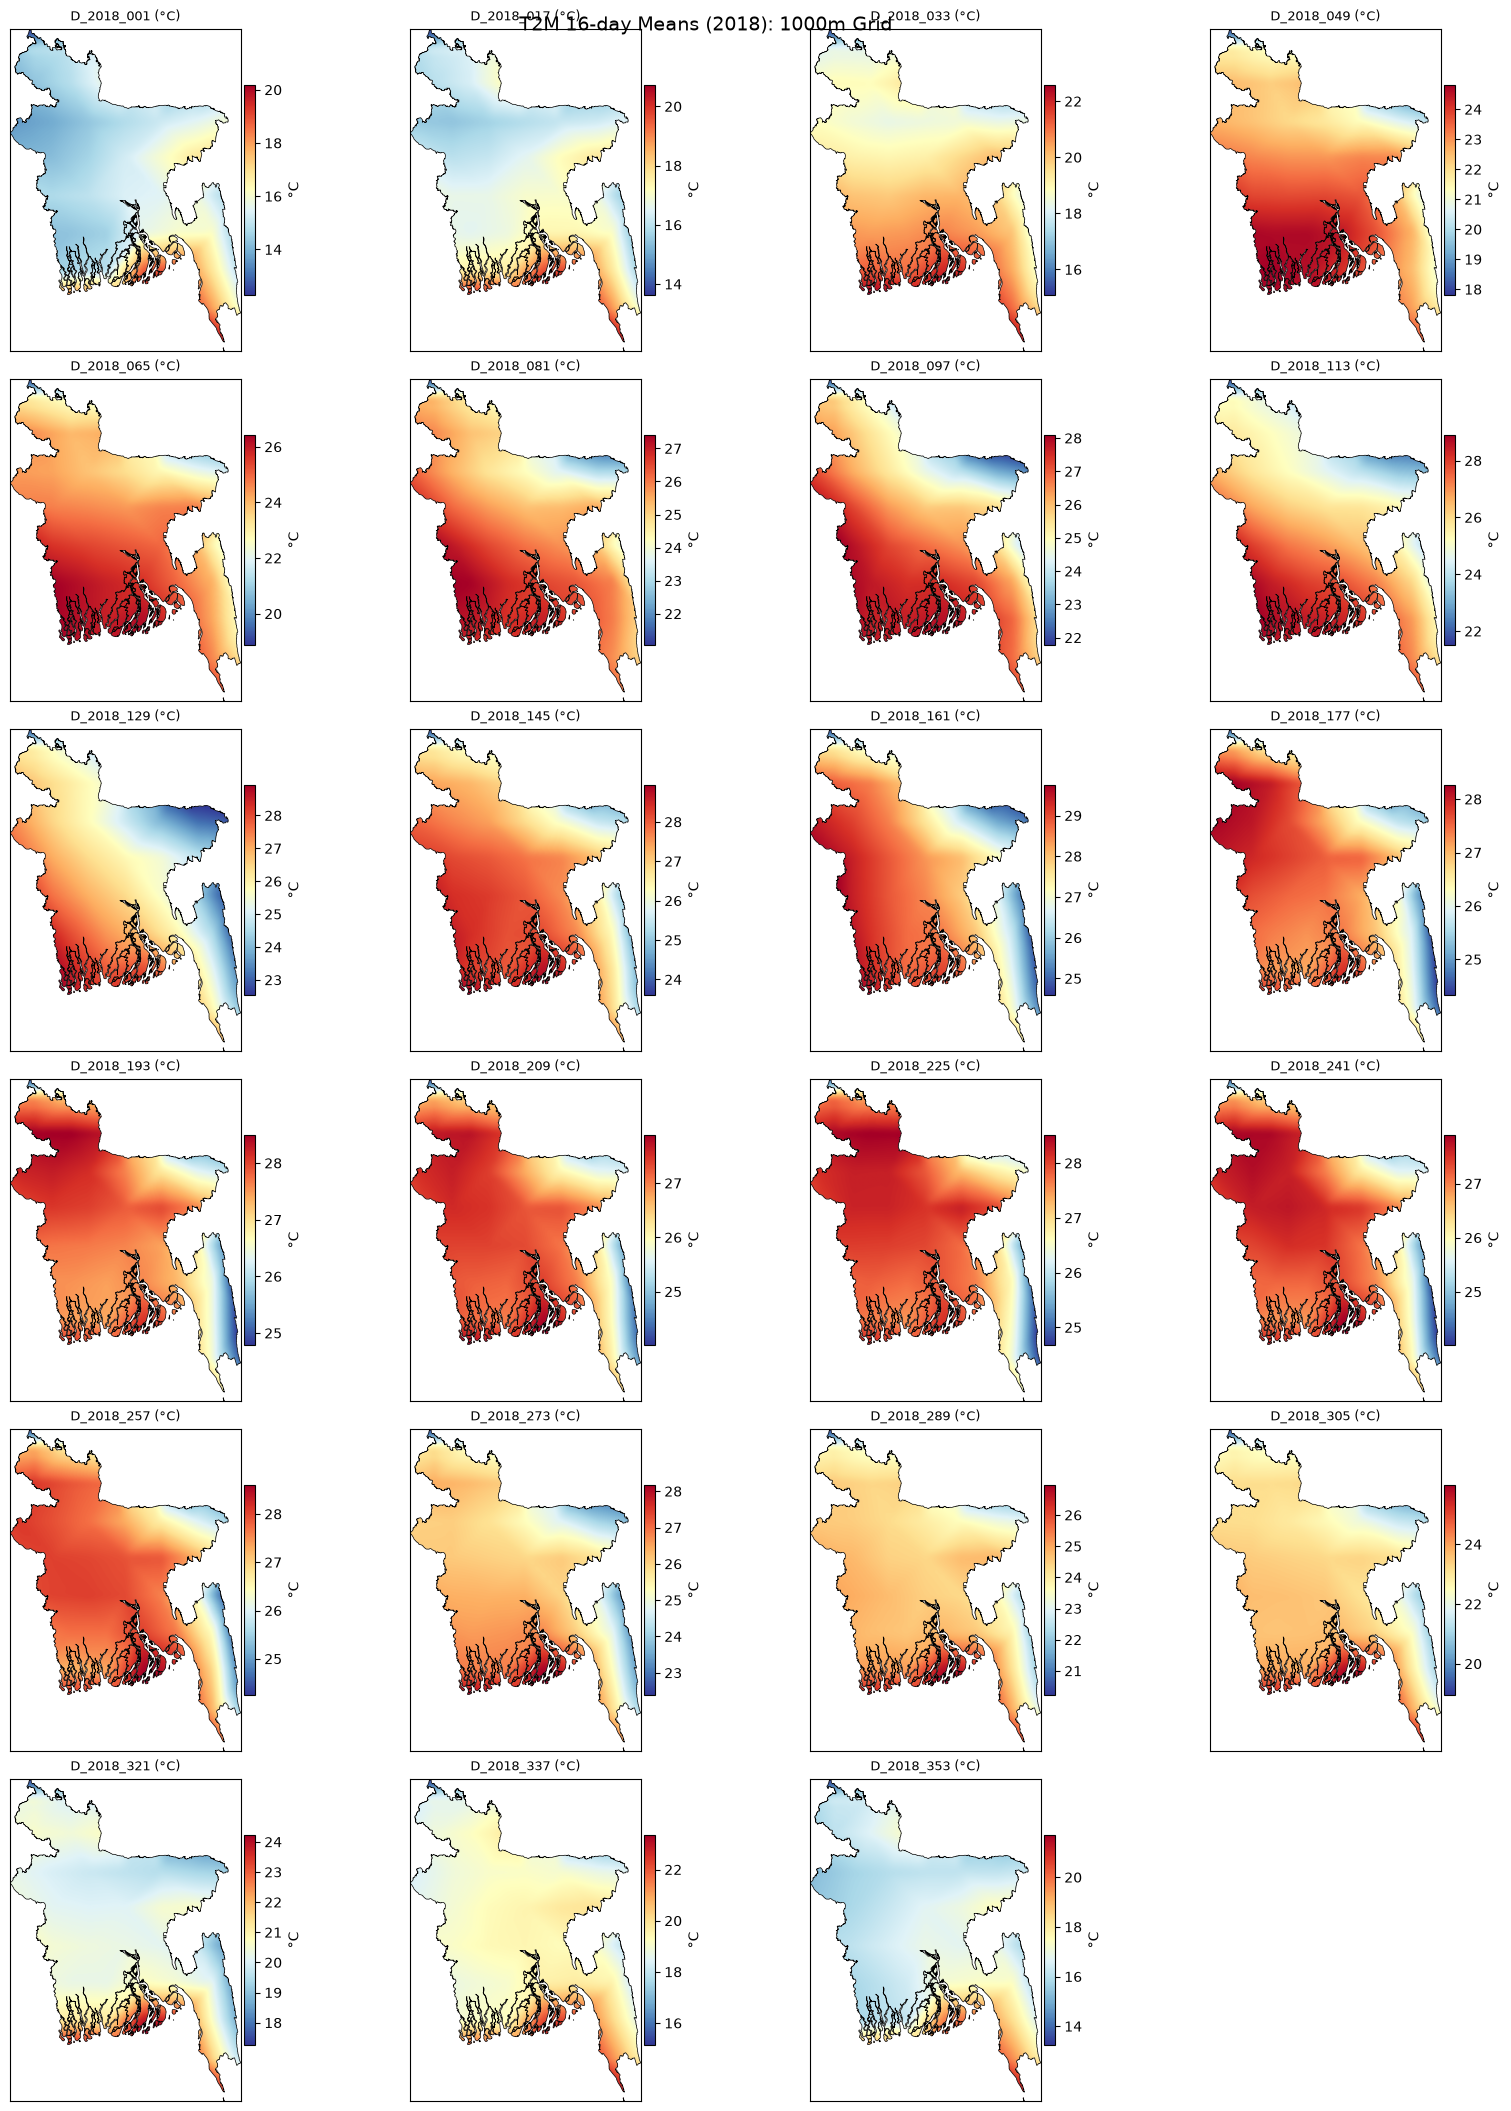

In [10]:

# Plot all bands (16-day tiffs) in a panel
n_bands = len(bands)  # n_bands
ncols = 4  # ncols
nrows = int(np.ceil(n_bands / ncols))  # compute nrows
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(16, 3.5*nrows), constrained_layout=True)  # create the figure and axes

extent = [bd.total_bounds[0], bd.total_bounds[2], bd.total_bounds[1], bd.total_bounds[3]]  # extent

for i, (arr, col) in enumerate(zip(bands, band_cols)):  # iterate over items
    ax = axes.flat[i]  # ax
    im = ax.imshow(arr, origin="upper", extent=extent, cmap="RdYlBu_r")  # show a 2-D array as an image
    bd.boundary.plot(ax=ax, color="k", linewidth=0.5, zorder=2)  # draw the map or chart
    ax.set_title(f"{col} (°C)", fontsize=9)  # panel title
    ax.set_xticks([])  # configure tick labels
    ax.set_yticks([])  # configure tick labels
    plt.colorbar(im, ax=ax, shrink=0.65, label="°C", pad=0.01)  # add a colorbar
# Hide remaining axes if bands don't fill the grid
for j in range(i + 1, nrows * ncols):  # iterate over items
    fig.delaxes(axes.flat[j])

plt.suptitle("T2M 16-day Means (2018): 1000m Grid", y=0.995, fontsize=14)
plt.show()  # render the figure


## Process all years

Repeat sections 5-10 for every year present in `t2m_2000_2018.nc`.
Set `RUN_ALL_YEARS = True` to write all CSVs and GeoTIFFs (takes a while).


In [11]:
RUN_ALL_YEARS = True  # set False to skip batch after the 2018 demo above

with xr.open_dataset(NC_PATH) as _ds:  # open a context-managed resource
    years_available = sorted(set(pd.to_datetime(_ds.time.values).year))  # parse timestamps

# Drop trailing Jan-1 spillover year if it has almost no data
years_available = [y for y in years_available if y <= 2018]  # years_available
print("Years to process:", years_available)  # status / summary print

if RUN_ALL_YEARS:
    grid_cache = make_target_grid(bd, RESOLUTION_M)  # grid_cache
    results = []  # results
    for year in years_available:  # iterate over items
        try:  # attempt optional or version-sensitive call
            results.append(
                process_year(
                    NC_PATH, year, bd, TAB_DIR, RAS_DIR, grid_cache, RESOLUTION_M
                )
            )
        except Exception as exc:  # handle the failure path
            print(f"  SKIP {year}: {exc}")  # status / summary print
    print("\nDone. Wrote", len(results), "year(s).")  # status / summary print
    print("Tabular:", TAB_DIR)  # status / summary print
    print("Raster: ", RAS_DIR)  # status / summary print
else:
    print("Batch skipped (RUN_ALL_YEARS=False). 2018 demo outputs already written.")  # status / summary print


Years to process: [2000, 2001, 2002, 2003, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018]



=== Year 2000 ===


  3-hourly: 2688 steps
  daily:    337 days


  points after clip: 797
  CSV → t2m_2000_mean_16days.csv  (23 composites)


  TPS D_2000_001


  TPS D_2000_017


... (399 outputs left out)

  TPS D_2018_321


  TPS D_2018_337


  TPS D_2018_353


  GeoTIFF → t2m_2018_16day_1000m.tif  (23 bands, 480×670 @ 1000 m)

Done. Wrote 16 year(s).
Tabular: /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/NetCDF/output/Tabular_Data
Raster:  /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/NetCDF/output/Raster_Data


## Raster to NetCDF

Convert the Bangladesh **watertable** GeoTIFF series under
`Data/00_shared/raster_data/Bangladesh/watertable/` into a multidimensional NetCDF with
`geolattice.spatial_analysis.multidimensional_raster` (ArcGIS-style **Raster to NetCDF**).

| Step | API / tool | Role |
|---|---|---|
| 1 | `rasterio` + `MultidimensionalRaster` | Read each `watertable_YYYY_DOY.tif` as a time slice |
| 2 | `merge_multidimensional_rasters` | Combine yearly cubes along `time` |
| 3 | `raster_to_netcdf` | Write the merged cube to NetCDF |

Filenames encode MODIS 16-day composites (`watertable_1985_001.tif` -> 1985-01-01).

**Output:** `Data/03_spatial_analysis/NetCDF/output/watertable_1985_2020.nc`

> **Note:** GeoTIFFs are opened with `rasterio` so this cell works in Jupyter without
> relying on the system `osgeo`/`libgdal` shared library. Re-run **Setup** first after
> a kernel restart.


In [12]:
# Raster to NetCDF: watertable GeoTIFF series -> multidimensional NetCDF
#
# Reads GeoTIFFs with rasterio (reliable in Jupyter), then wraps with
# geolattice MultidimensionalRaster + raster_to_netcdf.
import re  # regular expressions for filename / DOY parsing
from datetime import datetime, timedelta  # parse and construct timestamps

def parse_watertable_time(path: Path) -> datetime:
    """Parse watertable_YYYY_DOY.tif -> datetime at that day-of-year."""
    m = re.match(r"watertable_(\d{4})_(\d{3})$", path.stem)  # m
    if not m:
        raise ValueError(f"Unexpected watertable filename: {path.name}")  # fail with a clear error message
    year, doy = int(m.group(1)), int(m.group(2))  # year
    return datetime(year, 1, 1) + timedelta(days=doy - 1)  # return the computed result


def stack_geotiffs_to_mdr(paths, times, variable_name="watertable"):
    """Build a MultidimensionalRaster from a GeoTIFF time series (rasterio)."""
    arrays = []  # arrays
    xs = ys = None  # xs
    for path in paths:  # iterate over items
        with rasterio.open(path) as src:  # open a context-managed resource
            data = src.read(1).astype("float32")  # cast to the target dtype
            nodata = src.nodata  # nodata
            if nodata is not None:
                data = np.where(data == nodata, np.nan, data)  # compute data
            # also mask extreme GDAL nodata sentinels
            data = np.where(np.abs(data) > 1e30, np.nan, data)  # compute data
            transform = src.transform  # transform
            height, width = data.shape  # height
            xs = transform.c + (np.arange(width) + 0.5) * transform.a  # compute xs
            ys = transform.f + (np.arange(height) + 0.5) * transform.e  # compute ys
            arrays.append(data)

    da = xr.DataArray(  # da
        np.stack(arrays, axis=0),  # set np.stack(arrays
        dims=("time", "y", "x"),  # dims
        coords={"time": list(times), "y": ys, "x": xs},  # coords
        name=variable_name,  # name
    )
    return MultidimensionalRaster(da)  # return the computed result


# 1) List GeoTIFF slices
wt_tifs = sorted(WT_DIR.glob("watertable_*.tif"))  # collect matching files
print(f"Found {len(wt_tifs)} watertable GeoTIFFs in {WT_DIR}")  # status / summary print
if not wt_tifs:
    raise FileNotFoundError(f"No watertable_*.tif under {WT_DIR}")  # fail with a clear error message

years = sorted({int(p.stem.split("_")[1]) for p in wt_tifs})  # years
print(f"Years: {years[0]}-{years[-1]} ({len(years)} years)")  # status / summary print

# 2) Build one cube per year, write yearly NetCDF (keeps memory bounded)
yearly_nc = []  # yearly_nc
wt_year_dir = NC_OUT_DIR / "watertable_yearly"  # build a filesystem path
wt_year_dir.mkdir(parents=True, exist_ok=True)  # set wt_year_dir.mkdir(parents

for year in years:  # iterate over items
    paths = sorted(WT_DIR.glob(f"watertable_{year}_*.tif"))  # collect matching files
    times = [parse_watertable_time(p) for p in paths]  # times
    year_nc = wt_year_dir / f"watertable_{year}.nc"  # year_nc
    mdr_year = stack_geotiffs_to_mdr(paths, times, variable_name="watertable")  # build multidimensional layer
    raster_to_netcdf(
        mdr_year,
        year_nc,
        overwrite=True,  # overwrite
        encoding={"watertable": {"zlib": True, "complevel": 4, "dtype": "float32"}},  # encoding
    )
    yearly_nc.append(year_nc)
    print(f"  {year}: {len(paths)} slices -> {year_nc.name}")  # status / summary print

# 3) Merge along time and write combined NetCDF
WT_NC = NC_OUT_DIR / "watertable_1985_2020.nc"  # build a filesystem path
merged = merge_multidimensional_rasters(  # merged
    yearly_nc,
    dimension="time",  # dimension
    combine="by_coords",  # combine
)
ds = merged.dataset.copy(deep=False)  # ds
ds["watertable"] = ds["watertable"].astype("float32")  # set ds["watertable"]
ds["watertable"].attrs.update({
    "long_name": "Groundwater watertable depth / level",
    "units": "m",
})
ds.attrs.update({
    "title": "Bangladesh watertable 16-day series (1985-2020)",
    "source": str(WT_DIR),
    "Conventions": "CF-1.8",
})

raster_to_netcdf(
    MultidimensionalRaster(ds),
    WT_NC,
    overwrite=True,  # overwrite
    encoding={"watertable": {"zlib": True, "complevel": 4, "dtype": "float32"}},  # encoding
)

# 4) Verify 
chk = xr.open_dataset(WT_NC)  # open the NetCDF / dataset
print("\nWrote:", WT_NC)  # status / summary print
print(chk)  # status / summary print
print(f"size_mb={WT_NC.stat().st_size / 1e6:.1f}")  # status / summary print
print("time:", chk.time.values[0], "->", chk.time.values[-1], f"(n={chk.sizes['time']})")  # status / summary print


Found 828 watertable GeoTIFFs in /home/zia207/Github/GeoLattice/Data/00_shared/raster_data/Bangladesh/watertable
Years: 1985-2020 (36 years)


  1985: 23 slices -> watertable_1985.nc


  1986: 23 slices -> watertable_1986.nc


  1987: 23 slices -> watertable_1987.nc


  1988: 23 slices -> watertable_1988.nc


  1989: 23 slices -> watertable_1989.nc


... (28 outputs left out)

  2018: 23 slices -> watertable_2018.nc


  2019: 23 slices -> watertable_2019.nc


  2020: 23 slices -> watertable_2020.nc



Wrote: /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/NetCDF/output/watertable_1985_2020.nc
<xarray.Dataset> Size: 1GB
Dimensions:     (time: 828, y: 669, x: 479)
Coordinates:
  * time        (time) datetime64[ns] 7kB 1985-01-01 1985-01-17 ... 2020-12-18
  * y           (y) float64 5kB 2.946e+06 2.945e+06 ... 2.278e+06 2.277e+06
  * x           (x) float64 4kB 2.99e+05 3e+05 3.01e+05 ... 7.766e+05 7.776e+05
Data variables:
    watertable  (time, y, x) float32 1GB ...
Attributes:
    title:        Bangladesh watertable 16-day series (1985-2020)
    source:       /home/zia207/Github/GeoLattice/Data/00_shared/raster_data/B...
    Conventions:  CF-1.8
size_mb=287.1
time: 1985-01-01T00:00:00.000000000 -> 2020-12-18T00:00:00.000000000 (n=828)


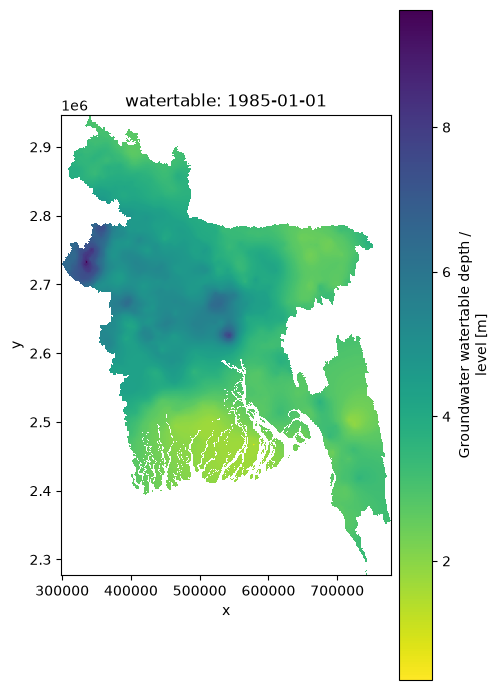

In [13]:

fig, ax = plt.subplots(figsize=(5, 7))  # create the figure and axes
im = chk["watertable"].isel(time=0).plot(  # select along coordinates or indices
    ax=ax,  # ax
    cmap="viridis_r",  # cmap
    cbar_kwargs={"shrink": 1.0, "aspect": 20, "pad": 0.02}  # cbar_kwargs
)
ax.set_title(f"watertable: {np.datetime_as_string(chk.time.values[0], unit='D')}")  # panel title
ax.set_aspect("equal")  # style the axes

# Adjust colorbar so its height matches the image
# Get colorbar from im; im.colorbar is a <matplotlib.colorbar.Colorbar> object
if hasattr(im, 'colorbar') and im.colorbar is not None:  # add a colorbar
    # Reduce color bar height and set it to match image height
    cbar = im.colorbar  # add a colorbar
    fig.canvas.draw()
    bbox = ax.get_position()  # bbox
    # Set colorbar height to match axes height, but limit to axes (may still be a bit taller due to padding/margins)
    # If still taller, shrink using aspect and shrink parameter as a fallback
    fig.canvas.draw()
    bbox = ax.get_position()  # bbox
    cbar_pos = cbar.ax.get_position()  # cbar_pos
    # Adjust colorbar height to match the axes height
    new_height = bbox.height  # Set new height to match axes (ax) height
    # Fix unclosed list and misplaced code
    cbar.ax.set_position([
        cbar_pos.x0,    # x0
        bbox.y0,        # y0 aligned with axes
        cbar_pos.width, # keep width
        new_height      # not taller than axes
    ])
    cbar.ax.set_aspect('auto')
    fig.tight_layout()  # reduce unused whitespace
    # Optionally, adjust once more to ensure height matches axes (can be removed if redundant)
    cbar.ax.set_position([
        cbar.ax.get_position().x0,   # keep x0
        bbox.y0,                     # align y0
        cbar.ax.get_position().width,
        bbox.height                  # set height to match axes
    ])

plt.tight_layout()  # reduce unused whitespace
plt.show()  # render the figure
chk.close()  # release the file handle


## Table to NetCDF

Export the 16-day `t2m` CSVs in `Data/03_spatial_analysis/NetCDF/output/Tabular_Data/` to NetCDF with
`geolattice.spatial_analysis.table_to_netcdf` (ArcGIS **Table to NetCDF**).

Each CSV has columns:

`station_id`, `lon`, `lat`, `D_YYYY_001`, `D_YYYY_017`, … `D_YYYY_353`

This section:

1. Loads one year (demo **2018**) and all yearly CSVs from `Tabular_Data`
2. Writes a **wide** table NetCDF (one variable per 16-day column)
3. Melts to **long** form (`station` x `time`) and writes an analysis-friendly NetCDF
4. Optionally stacks every year into one multi-year long-form NetCDF

**Outputs** (under `Data/03_spatial_analysis/NetCDF/output/`):

| File | Content |
|---|---|
| `t2m_2018_table_wide.nc` | Wide table via `table_to_netcdf` |
| `t2m_2018_table_long.nc` | Long `station` x `time` cube |
| `t2m_all_years_table_long.nc` | All years stacked |


Found 16 CSV files in /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/NetCDF/output/Tabular_Data
  t2m_2000_mean_16days.csv
  t2m_2001_mean_16days.csv
  t2m_2002_mean_16days.csv
  t2m_2003_mean_16days.csv
  t2m_2007_mean_16days.csv
  t2m_2008_mean_16days.csv
  t2m_2009_mean_16days.csv
  t2m_2010_mean_16days.csv
  t2m_2011_mean_16days.csv
  t2m_2012_mean_16days.csv
  t2m_2013_mean_16days.csv
  t2m_2014_mean_16days.csv
  t2m_2015_mean_16days.csv
  t2m_2016_mean_16days.csv
  t2m_2017_mean_16days.csv
  t2m_2018_mean_16days.csv

Demo table t2m_2018_mean_16days.csv: (797, 26)
  station_id     lon     lat  D_2018_001  D_2018_017  D_2018_033  D_2018_049  \
0      S1573  89.375  21.750   17.507720   19.554756   22.312443   24.694998   
1      S1572  89.250  21.750   17.456564   19.539871   22.332142   24.720406   
2      S1531  89.250  21.875   16.479610   18.828053   21.950613   24.752777   

   D_2018_065  D_2018_081  D_2018_097  ...  D_2018_209  D_2018_225  \
0   26.201729   26.92434


All-years long table: (293296, 5)


All-years record NetCDF -> /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/NetCDF/output/t2m_all_years_table_records.nc
All-years long cube -> /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/NetCDF/output/t2m_all_years_table_long.nc
<xarray.Dataset> Size: 1MB
Dimensions:  (time: 359, station: 797)
Coordinates:
  * time     (time) datetime64[ns] 3kB 2000-01-01 2000-01-17 ... 2018-12-19
  * station  (station) <U5 16kB 'S0007' 'S0008' 'S0050' ... 'S1800' 'S1842'
    lon      (station) float64 6kB ...
    lat      (station) float64 6kB ...
Data variables:
    t2m      (time, station) float32 1MB ...
time: 2000-01-01T00:00:00.000000000 -> 2018-12-19T00:00:00.000000000 (n=359)
stations: 797


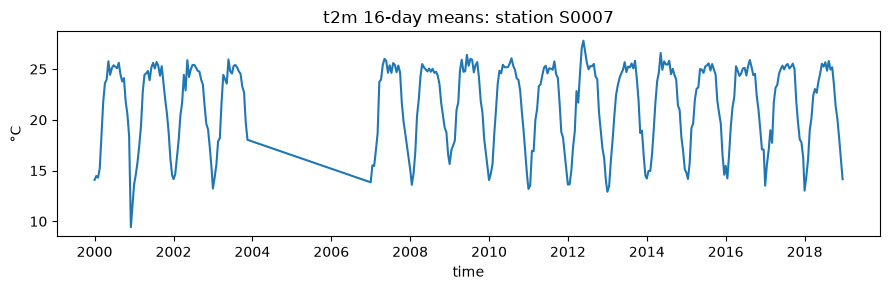

In [14]:
# Table to NetCDF: use CSVs from Data/03_spatial_analysis/NetCDF/output/Tabular_Data
import re  # regular expressions for filename / DOY parsing
from datetime import datetime, timedelta  # parse and construct timestamps

csv_files = sorted(TAB_DIR.glob("t2m_*_mean_16days.csv"))  # collect matching files
print(f"Found {len(csv_files)} CSV files in {TAB_DIR}")  # status / summary print
for pth in csv_files:  # iterate over items
    print(" ", pth.name)  # status / summary print

demo_csv = TAB_DIR / f"t2m_{DEMO_YEAR}_mean_16days.csv"  # demo_csv
if not demo_csv.is_file():  # only when the path exists
    raise FileNotFoundError(  # fail with a clear error message
        f"Missing {demo_csv}. Run the 16-day CSV steps (section 5 / 7) first."
    )

table = pd.read_csv(demo_csv)  # compute table
print(f"\nDemo table {demo_csv.name}: {table.shape}")  # status / summary print
print(table.head(3))  # status / summary print


def composite_col_to_time(col: str) -> datetime:
    """D_2018_017 -> datetime for that year + DOY."""
    m = re.match(r"D_(\d{4})_(\d{3})$", col)  # m
    if not m:
        raise ValueError(f"Unexpected composite column: {col}")  # fail with a clear error message
    year, doy = int(m.group(1)), int(m.group(2))  # year
    return datetime(year, 1, 1) + timedelta(days=doy - 1)  # return the computed result


def wide_to_long(df: pd.DataFrame) -> pd.DataFrame:
    """Melt D_YYYY_DOY columns to station_id, lon, lat, time, t2m."""
    id_vars = ["station_id", "lon", "lat"]  # id_vars
    value_vars = [c for c in df.columns if re.match(r"D_\d{4}_\d{3}$", c)]  # value_vars
    long = df.melt(id_vars=id_vars, value_vars=value_vars, var_name="composite", value_name="t2m")  # long
    long["time"] = long["composite"].map(composite_col_to_time)  # set long["time"]
    return long.drop(columns=["composite"]).sort_values(["station_id", "time"]).reset_index(drop=True)  # return the computed result


# ---------------------------------------------------------------------------
# A) Wide table -> NetCDF (ArcGIS Table to NetCDF style)
# ---------------------------------------------------------------------------
wide_nc = NC_OUT_DIR / f"t2m_{DEMO_YEAR}_table_wide.nc"  # wide_nc
# Keep a clean numeric index for the row dimension
wide_df = table.copy()  # wide_df
# station_id as a column variable; use RangeIndex as record dim
wide_df = wide_df.reset_index(drop=True)  # wide_df
table_to_netcdf(wide_df, wide_nc, row_dimension="record", overwrite=True)  # set table_to_netcdf(wide_df
print(f"\nWide NetCDF -> {wide_nc}")  # status / summary print
print(xr.open_dataset(wide_nc))  # status / summary print


# ---------------------------------------------------------------------------
# B) Long station x time cube (better for analysis)
# ---------------------------------------------------------------------------
long_df = wide_to_long(table)  # long_df
print(f"\nLong table: {long_df.shape}")  # status / summary print
print(long_df.head(3))  # status / summary print

# Pivot to (time, station) DataArray, then write via MultidimensionalRaster helper path
stations = long_df["station_id"].astype(str)  # cast to the target dtype
lon_by_st = long_df.drop_duplicates("station_id").set_index("station_id")["lon"]  # lon_by_st
lat_by_st = long_df.drop_duplicates("station_id").set_index("station_id")["lat"]  # lat_by_st

pivot = long_df.pivot(index="time", columns="station_id", values="t2m").sort_index()  # pivot
da = xr.DataArray(  # da
    pivot.to_numpy(dtype="float32"),  # set pivot.to_numpy(dtype
    dims=("time", "station"),  # dims
    coords={  # coords
        "time": pivot.index.to_numpy(),
        "station": pivot.columns.astype(str).to_numpy(),
        "lon": ("station", lon_by_st.loc[pivot.columns].to_numpy()),
        "lat": ("station", lat_by_st.loc[pivot.columns].to_numpy()),
    },
    name="t2m",  # name
    attrs={"units": "degC", "long_name": "16-day mean 2 metre temperature"},  # attrs
)
long_nc = NC_OUT_DIR / f"t2m_{DEMO_YEAR}_table_long.nc"  # long_nc
da.to_dataset().to_netcdf(
    long_nc,
    encoding={"t2m": {"zlib": True, "complevel": 4, "dtype": "float32"}},  # encoding
)
print(f"Long NetCDF -> {long_nc}")  # status / summary print
print(xr.open_dataset(long_nc))  # status / summary print


# ---------------------------------------------------------------------------
# C) All years from Tabular_Data -> one long NetCDF
# ---------------------------------------------------------------------------
frames = []  # frames
for csv_path in csv_files:  # iterate over items
    frames.append(wide_to_long(pd.read_csv(csv_path)))
all_long = pd.concat(frames, ignore_index=True)  # compute all_long
print(f"\nAll-years long table: {all_long.shape}")  # status / summary print

# Also export the concatenated long table with table_to_netcdf (record form)
all_table_nc = NC_OUT_DIR / "t2m_all_years_table_records.nc"  # build a filesystem path
table_to_netcdf(
    all_long.assign(time=all_long["time"].astype("datetime64[ns]")),  # set all_long.assign(time
    all_table_nc,
    row_dimension="record",  # row_dimension
    overwrite=True,  # overwrite
)
print(f"All-years record NetCDF -> {all_table_nc}")  # status / summary print

# Station x time cube for all years
pivot_all = all_long.pivot_table(index="time", columns="station_id", values="t2m", aggfunc="mean").sort_index()  # pivot_all
lon_all = all_long.drop_duplicates("station_id").set_index("station_id")["lon"]  # lon_all
lat_all = all_long.drop_duplicates("station_id").set_index("station_id")["lat"]  # lat_all
da_all = xr.DataArray(  # da_all
    pivot_all.to_numpy(dtype="float32"),  # set pivot_all.to_numpy(dtype
    dims=("time", "station"),  # dims
    coords={  # coords
        "time": pivot_all.index.to_numpy(),
        "station": pivot_all.columns.astype(str).to_numpy(),
        "lon": ("station", lon_all.loc[pivot_all.columns].to_numpy()),
        "lat": ("station", lat_all.loc[pivot_all.columns].to_numpy()),
    },
    name="t2m",  # name
    attrs={"units": "degC", "long_name": "16-day mean 2 metre temperature"},  # attrs
)
all_long_nc = NC_OUT_DIR / "t2m_all_years_table_long.nc"  # build a filesystem path
da_all.to_dataset().to_netcdf(
    all_long_nc,
    encoding={"t2m": {"zlib": True, "complevel": 4, "dtype": "float32"}},  # encoding
)
print(f"All-years long cube -> {all_long_nc}")  # status / summary print
chk = xr.open_dataset(all_long_nc)  # open the NetCDF / dataset
print(chk)  # status / summary print
print("time:", chk.time.values[0], "->", chk.time.values[-1], f"(n={chk.sizes['time']})")  # status / summary print
print("stations:", chk.sizes["station"])  # status / summary print

# Quick plot: one station time series
st0 = str(chk.station.values[0])  # st0
fig, ax = plt.subplots(figsize=(9, 3))  # create the figure and axes
chk["t2m"].sel(station=st0).plot(ax=ax)  # draw the map or chart
ax.set_title(f"t2m 16-day means: station {st0}")  # panel title
ax.set_ylabel("°C")  # y-axis label
plt.tight_layout()  # reduce unused whitespace
plt.show()  # render the figure
chk.close()  # release the file handle


## Summary

| Step | Action | Output |
|---|---|---|
| 1 | Extract `t2m` year | in-memory DataArray (°C) |
| 2 | 3-hourly -> daily mean | daily cube |
| 3-4 | Points -> BUTM -> clip | station points in BD |
| 5 | MODIS 16-day means | `Tabular_Data/t2m_YYYY_mean_16days.csv` |
| 6 | TPS @ 1000 m multi-band | `Raster_Data/t2m_YYYY_16day_1000m.tif` |
| Raster to NetCDF | watertable GeoTIFF series | `output/watertable_1985_2020.nc` |
| Table to NetCDF | `Tabular_Data` CSVs -> NetCDF | `t2m_*_table_*.nc` |

CSV columns: `station_id`, `lon`, `lat`, `D_YYYY_001`, `D_YYYY_017`, `D_YYYY_033`, …

APIs: `build_multidimensional_info`, `merge_multidimensional_rasters`, `raster_to_netcdf`, `table_to_netcdf`

Reference implementation: `R_Code/t2m_netCDF_data_processing.py`.


## Further reading

- [xarray documentation](https://docs.xarray.dev/)
- [rasterio documentation](https://rasterio.readthedocs.io/)
- [geopandas documentation](https://geopandas.org/)
- [netCDF4 Python package](https://unidata.github.io/netcdf4-python/)
- MODIS Data Product Information: [LP DAAC MODIS Overview](https://lpdaac.usgs.gov/products/modis_products_table/)
- [Python in Hydrology and Climate Sciences](https://earth-env-data-science.github.io/lectures/netcdf_intro.html)
